# Baseline Model: TF-IDF + Logistic Regression

This notebook implements a simple baseline for AI-generated text detection.

## Pipeline
1. Load preprocessed train / validation / test splits
2. Build a TF-IDF + Logistic Regression pipeline
3. Train the baseline model
4. Evaluate on validation and test sets
5. Show confusion matrix and sample prediction confidence
6. Save the trained baseline model

## Input files
- `datasets/splits/train.parquet`
- `datasets/splits/val.parquet`
- `datasets/splits/test.parquet`

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =========================
# Path fix (VERY IMPORTANT)
# =========================
train_path = "../datasets/splits/train.parquet"
val_path   = "../datasets/splits/val.parquet"
test_path  = "../datasets/splits/test.parquet"

# check path
for path in [train_path, val_path, test_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

# =========================
# Load data
# =========================
train_df = pd.read_parquet(train_path)
val_df   = pd.read_parquet(val_path)
test_df  = pd.read_parquet(test_path)

print("Train:", train_df.shape)
print("Val  :", val_df.shape)
print("Test :", test_df.shape)

# =========================
# Prepare data
# =========================
X_train = train_df["text"].astype(str)
y_train = train_df["label"].astype(int)

X_val = val_df["text"].astype(str)
y_val = val_df["label"].astype(int)

X_test = test_df["text"].astype(str)
y_test = test_df["label"].astype(int)

label_map = {
    0: "Human-written",
    1: "AI-generated"
}


Train: (985525, 3)
Val  : (211184, 3)
Test : (211185, 3)


In [3]:
# =========================
# Build + Train model
# =========================

baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 1),
        max_features=8000
    )),
    ("clf", LogisticRegression(
        max_iter=200,
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)

print("Training complete.")

Training complete.



===== Validation Results =====
Accuracy : 0.8957
Precision: 0.8136
Recall   : 0.7855
F1-score : 0.7993

              precision    recall  f1-score   support

           0     0.9239    0.9353    0.9296    155352
           1     0.8136    0.7855    0.7993     55832

    accuracy                         0.8957    211184
   macro avg     0.8687    0.8604    0.8644    211184
weighted avg     0.8947    0.8957    0.8951    211184


===== Test Results =====
Accuracy : 0.8962
Precision: 0.8150
Recall   : 0.7860
F1-score : 0.8002

              precision    recall  f1-score   support

           0     0.9241    0.9359    0.9299    155352
           1     0.8150    0.7860    0.8002     55833

    accuracy                         0.8962    211185
   macro avg     0.8695    0.8609    0.8651    211185
weighted avg     0.8952    0.8962    0.8956    211185



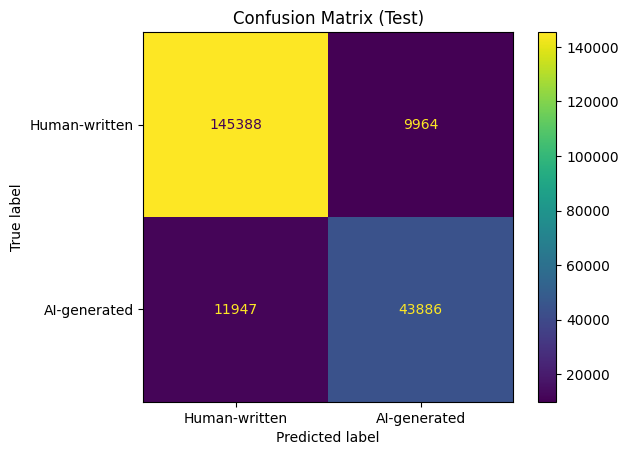

In [4]:
# =========================
# Evaluation function
# =========================

def evaluate(model, X, y, name="Test"):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]

    acc = accuracy_score(y, pred)
    precision = precision_score(y, pred, zero_division=0)
    recall = recall_score(y, pred, zero_division=0)
    f1 = f1_score(y, pred, zero_division=0)

    print(f"\n===== {name} Results =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print()
    print(classification_report(y, pred, digits=4))

    return pred, prob


# =========================
# Validation
# =========================
val_pred, val_prob = evaluate(baseline_model, X_val, y_val, "Validation")

# =========================
# Test
# =========================
test_pred, test_prob = evaluate(baseline_model, X_test, y_test, "Test")

# =========================
# Confusion Matrix
# =========================
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human-written", "AI-generated"]
)

disp.plot()
plt.title("Confusion Matrix (Test)")
plt.show()

In [5]:
# =========================
# Example prediction
# =========================

sample_text = "This essay explores the impact of artificial intelligence on education."

pred = baseline_model.predict([sample_text])[0]
proba = baseline_model.predict_proba([sample_text])[0]
confidence = proba[pred]

print("Input:", sample_text)
print("Prediction:", label_map[pred])
print("Confidence:", round(confidence, 4))


# =========================
# Save model
# =========================

joblib.dump(baseline_model, "baseline_model.joblib")
print("\nModel saved as baseline_model.joblib")

Input: This essay explores the impact of artificial intelligence on education.
Prediction: Human-written
Confidence: 0.9708

Model saved as baseline_model.joblib
